In [1]:
# ==========================================
# Cell 1: Imports and Test Directory Setup
# ==========================================
import os
import glob
import pickle
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
from tqdm import tqdm
from lsst.daf.butler import Butler
from slsim.LsstSciencePipeline import lsst_science_pipeline

from utils import (
    extract_lens_properties, robust_batch_lens_injection, patch_is_crowded,
    plot_injected_montage, plot_noise_std_histograms,
)

import warnings
warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

img_dir = "../data_injected_test/lenses/images/"
os.makedirs(img_dir, exist_ok=True)


In [2]:
# ==========================================
# Cell 2: Load a Small Test Batch of Lenses
# ==========================================
num_test_lenses = 300  # bump this up/down as needed

lens_files = sorted(glob.glob("../saved_objects/lensed_quasars_balanced_*.pkl"))

lensed_quasars_test = []
for file in lens_files:
    with open(file, "rb") as f:
        lensed_quasars_test.extend(pickle.load(f))
    if len(lensed_quasars_test) >= num_test_lenses:
        break

lensed_quasars_test = lensed_quasars_test[:num_test_lenses]
print(f"Loaded {len(lensed_quasars_test)} lenses for the test run.")


Loaded 300 lenses for the test run.


In [3]:
# ==========================================
# Cell 3: Extract Properties for the Test Batch
# ==========================================
table_test = extract_lens_properties(
    lensed_quasars_test, all_bands=['g', 'r', 'i', 'z', 'y'], max_num_images=5
)


Extracting lens properties: 100%|██████████| 300/300 [00:43<00:00,  6.89it/s]


In [4]:
# ==========================================
# Cell 4: Initialize Butler and Injection Parameters
# ==========================================
print("Initializing Butler...")
butler = Butler("dp02", collections="2.2i/runs/DP0.2")

band_list = ['g', 'r', 'i', 'z', 'y']
num_pix = 41
pixel_scale = 0.2
transform_matrix = np.array([[pixel_scale, 0], [0, pixel_scale]])
lenses_per_patch = 250


Initializing Butler...


In [5]:
# ==========================================
# Cell 5: Inject the Test Batch
# ==========================================
pending_indices = list(range(len(lensed_quasars_test)))
successful_indices = []
attempt_counts = {}
max_patch_attempts = 15  # bounded so a bad patch can't hang the test run

with tqdm(total=len(lensed_quasars_test)) as pbar:
    while pending_indices:
        batch_indices = pending_indices[:lenses_per_patch]
        remaining = pending_indices[lenses_per_patch:]
        current_batch = [lensed_quasars_test[i] for i in batch_indices]

        ra = np.random.uniform(55.0, 70.0)
        dec = np.random.uniform(-43.0, -30.0)

        try:
            coadd_list, coadd_nImage_list, _, variance_map_list = lsst_science_pipeline.get_dp0_images(
                butler=butler, ra=ra, dec=dec, band_list=band_list, coadd_injection=True
            )
            mag_zero_list = [2.5 * np.log10(c.getPhotoCalib().getInstFluxAtZeroMagnitude()) for c in coadd_list]
        except Exception:
            continue

        # Cheap pre-check: skip whole patches too crowded to be worth a full attempt
        if patch_is_crowded(coadd_list, variance_map_list, band_list, pixel_scale, num_pix):
            continue

        # lens_ids=batch_indices: match results back to the table by row index,
        # NOT by lens.generate_id() - that string is built from a couple of
        # rounded physical parameters and is not guaranteed unique across a
        # large/"balanced" sample, so it can silently collide between objects.
        batch_results, batch_failures = robust_batch_lens_injection(
            lens_batch=current_batch,
            lens_ids=batch_indices,
            num_pix=num_pix,
            coadd_list=coadd_list,
            coadd_nImage_list=coadd_nImage_list,
            mag_zero_list=mag_zero_list,
            variance_map_list=variance_map_list,
            transform_matrix=transform_matrix,
            band_list=band_list,
            coadd_year=1,
            max_retries=10,
            snr_threshold=5,
            verbose=False,
        )

        succeeded_indices = set()
        for sample in batch_results:
            idx = sample["row_id"]
            obj_id = table_test[idx]["Lens ID"]
            table_test[idx]["RA"] = sample["cutout_center"][0]
            table_test[idx]["Dec"] = sample["cutout_center"][1]

            for band in band_list:
                fits_path = os.path.join(img_dir, f"{obj_id}_{band}.fits")
                fits.writeto(fits_path, sample["injected_images"][band], overwrite=True)

            successful_indices.append(idx)
            succeeded_indices.add(idx)
            pbar.update(1)

        # Split failures: a real exception won't be fixed by trying elsewhere,
        # so drop those immediately and surface the error. Location-based
        # failures still get requeued for a fresh patch.
        still_pending = []
        for i in batch_indices:
            if i in succeeded_indices:
                continue
            reason = batch_failures.get(i, "unknown")
            obj_id_i = table_test[i]["Lens ID"]
            if reason.startswith("exception"):
                tqdm.write(f"Dropping {obj_id_i} (index {i}) permanently - {reason}")
                continue
            attempt_counts[i] = attempt_counts.get(i, 0) + 1
            if attempt_counts[i] >= max_patch_attempts:
                tqdm.write(f"Warning: giving up on {obj_id_i} (index {i}) after {max_patch_attempts} patch attempts ({reason}).")
                continue
            still_pending.append(i)

        tqdm.write(f"Patch: {len(succeeded_indices)}/{len(batch_indices)} injected, {len(still_pending)} requeued.")
        pending_indices = remaining + still_pending

print(f"Injected {len(successful_indices)}/{len(lensed_quasars_test)} test lenses.")


 83%|████████▎ | 250/300 [05:31<00:04, 11.98it/s]  

Patch: 250/250 injected, 0 requeued.


100%|██████████| 300/300 [07:33<00:00,  1.51s/it]


Patch: 50/50 injected, 0 requeued.
Injected 300/300 test lenses.


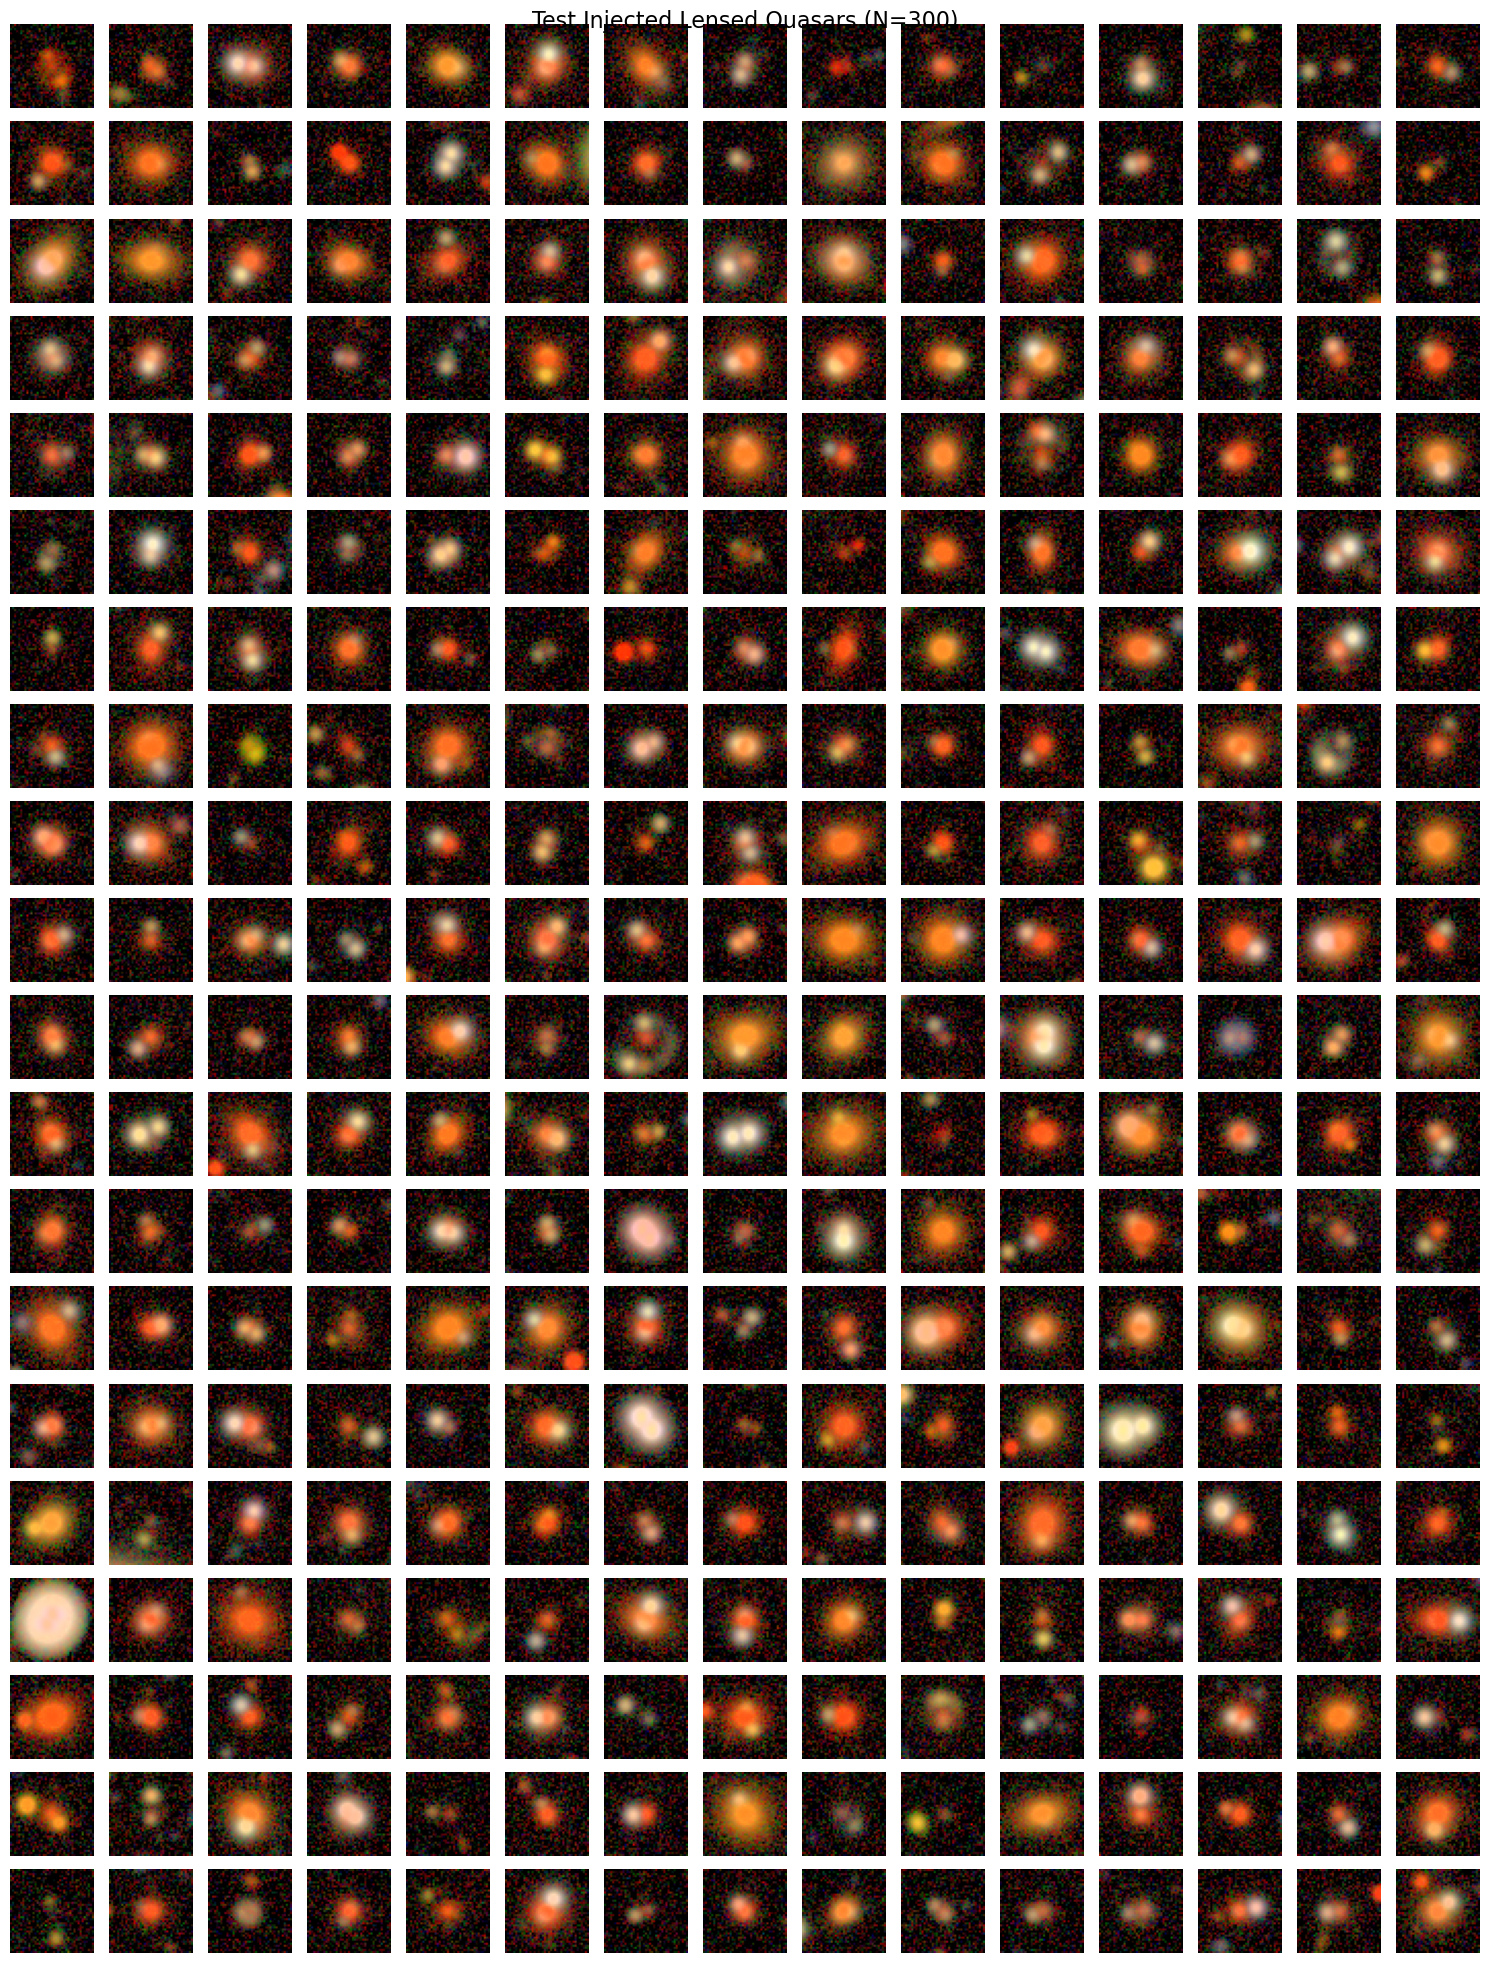

In [6]:
# ==========================================
# Cell 6: Montage - Visualize Injected Lenses
# ==========================================
test_ids = [table_test[i]["Lens ID"] for i in sorted(successful_indices)]

plot_injected_montage(
    test_ids,
    img_dir,
    band_list=band_list,
    rgb_bands=['i', 'r', 'g'],
    num_cols=15,
    plot_title=f"Test Injected Lensed Quasars (N={len(test_ids)})",
)
plt.show()


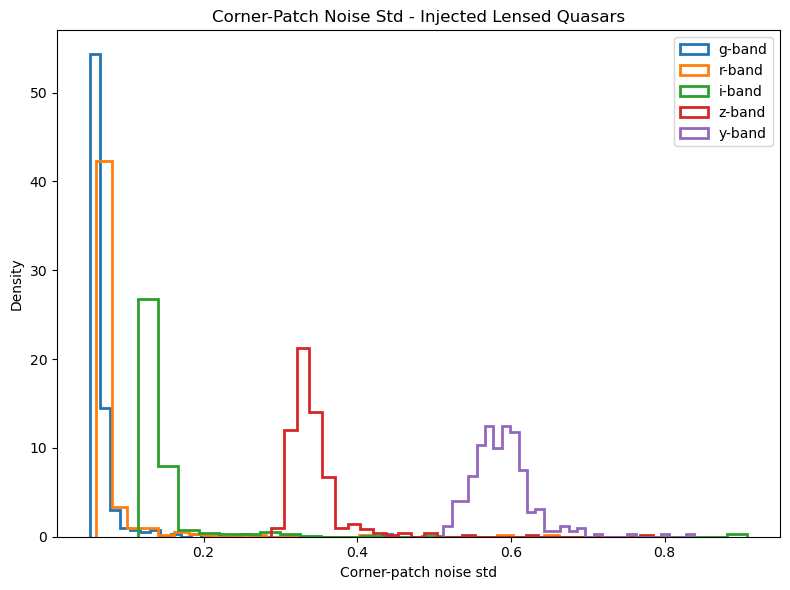

In [7]:
# ==========================================
# Cell 7: Noise Check - Corner-Patch Noise Std per Band
# ==========================================
plot_noise_std_histograms(
    test_ids,
    img_dir,
    band_list=band_list,
    corner_size=9,
    plot_title="Corner-Patch Noise Std - Injected Lensed Quasars",
)
plt.show()
